In [1]:
import pandas as pd 

from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression

In [2]:
%pip install pandas scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
housing = datasets.fetch_california_housing()

In [4]:
housing

{'data': array([[   8.3252    ,   41.        ,    6.98412698, ...,    2.55555556,
           37.88      , -122.23      ],
        [   8.3014    ,   21.        ,    6.23813708, ...,    2.10984183,
           37.86      , -122.22      ],
        [   7.2574    ,   52.        ,    8.28813559, ...,    2.80225989,
           37.85      , -122.24      ],
        ...,
        [   1.7       ,   17.        ,    5.20554273, ...,    2.3256351 ,
           39.43      , -121.22      ],
        [   1.8672    ,   18.        ,    5.32951289, ...,    2.12320917,
           39.43      , -121.32      ],
        [   2.3886    ,   16.        ,    5.25471698, ...,    2.61698113,
           39.37      , -121.24      ]], shape=(20640, 8)),
 'target': array([4.526, 3.585, 3.521, ..., 0.923, 0.847, 0.894], shape=(20640,)),
 'frame': None,
 'target_names': ['MedHouseVal'],
 'feature_names': ['MedInc',
  'HouseAge',
  'AveRooms',
  'AveBedrms',
  'Population',
  'AveOccup',
  'Latitude',
  'Longitude'],
 'DESCR': 

In [5]:
df = pd.DataFrame(housing.data, columns=housing.feature_names)

In [6]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [7]:
print(housing.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib:
https://lib.stat.cmu.edu/datasets/houses.zip

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per census
block group. A block g

In [8]:
dfTarget = pd.DataFrame(housing.target, columns=housing.target_names)

In [9]:
dfTarget.head()

,MedHouseVal
0,4.526
1,3.585
2,3.521
3,3.413
4,3.422


In [10]:
X = df
Y = dfTarget

In [11]:
X_train,X_test , Y_train,Y_test = train_test_split(X, Y, test_size=0.2, random_state=123)

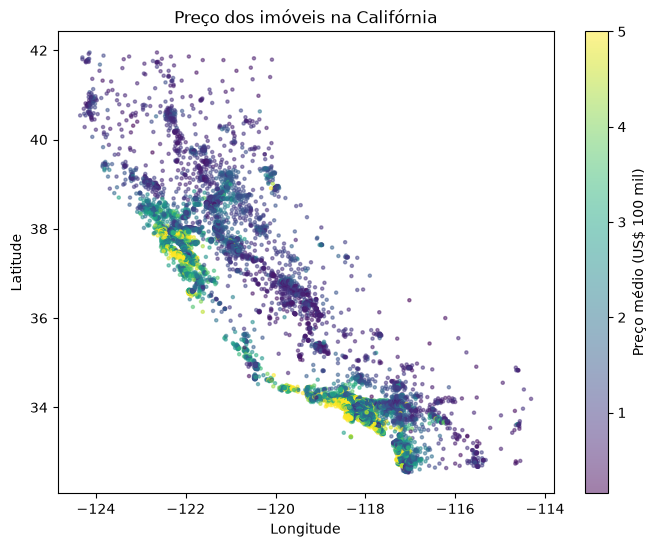

In [25]:
import matplotlib.pyplot as plt

dados = df.copy()
dados["Preco"] = housing.target

plt.figure(figsize=(8, 6))
plt.scatter(dados["Longitude"], dados["Latitude"], c=dados["Preco"],
            cmap="viridis", s=5, alpha=0.5)
plt.colorbar(label="Preço médio (US$ 100 mil)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Preço dos imóveis na Califórnia")
plt.show()

### Localização x preço
Os imóveis mais valorizados se concentram no litoral, nas regiões de São Francisco e Los Angeles. O interior apresenta preços bem mais baixos. Essa relação não linear entre localização e preço ajuda a explicar o melhor desempenho dos modelos baseados em árvores.

In [26]:
dados.corr()["Preco"].sort_values(ascending=False)

Preco         1.000000
MedInc        0.688075
AveRooms      0.151948
HouseAge      0.105623
AveOccup     -0.023737
Population   -0.024650
Longitude    -0.045967
AveBedrms    -0.046701
Latitude     -0.144160
Name: Preco, dtype: float64

In [12]:
X_train

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
9950,4.5694,28.0,6.219512,1.030488,504.0,3.073171,38.38,-122.33
3547,5.6392,18.0,5.951644,1.034816,3010.0,2.911025,34.26,-118.60
4448,1.7292,47.0,3.628032,1.032345,1452.0,3.913747,34.07,-118.21
6984,4.6226,36.0,5.126238,0.985149,988.0,2.445545,33.96,-118.02
4432,2.4375,49.0,4.024390,0.942073,1405.0,4.283537,34.08,-118.20
...,...,...,...,...,...,...,...,...
7763,3.6389,36.0,5.584615,1.115385,490.0,3.769231,33.91,-118.10
15377,4.5391,14.0,6.016688,1.017972,2436.0,3.127086,33.37,-117.24
17730,5.6306,5.0,5.958393,1.031564,2435.0,3.493544,37.33,-121.76
15725,3.8750,44.0,4.739264,1.024540,561.0,1.720859,37.78,-122.44


In [13]:
Y_train

,MedHouseVal
9950,2.875
3547,2.715
4448,1.917
6984,2.197
4432,1.140
...,...
7763,1.676
15377,1.809
17730,2.862
15725,4.125


In [14]:
scaler = StandardScaler()

In [15]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [16]:
reg = LinearRegression().fit(X_train_scaled,Y_train)

In [17]:
results = reg.predict(X_test_scaled)

In [19]:
results

array([[2.37757165],
       [1.43565121],
       [2.03589767],
       ...,
       [0.96892389],
       [1.72281529],
       [3.17568838]], shape=(4128, 1))

In [20]:
reg.score(X_test_scaled, Y_test)

0.6104546894797875

In [21]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

reg = LinearRegression().fit(X_train_scaled, Y_train)
pred = reg.predict(X_test_scaled)

print("RMSE:", np.sqrt(mean_squared_error(Y_test, pred)))
print("MAE: ", mean_absolute_error(Y_test, pred))
print("R²:  ", r2_score(Y_test, pred))

RMSE: 0.7197380534040614
MAE:  0.5255457157103739
R²:   0.6104546894797875


In [23]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

modelos = {
    "Regressão Linear": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=123, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=123),
}

resultados = []
for nome, modelo in modelos.items():
    modelo.fit(X_train_scaled, Y_train.values.ravel())
    p = modelo.predict(X_test_scaled)
    resultados.append({
        "Modelo": nome,
        "RMSE": np.sqrt(mean_squared_error(Y_test, p)),
        "MAE": mean_absolute_error(Y_test, p),
        "R²": r2_score(Y_test, p),
    })

pd.DataFrame(resultados).sort_values("RMSE")

,Modelo,RMSE,MAE,R²
1,Random Forest,0.498996,0.324103,0.812758
2,Gradient Boosting,0.518484,0.359890,0.797847
0,Regressão Linear,0.719738,0.525546,0.610455


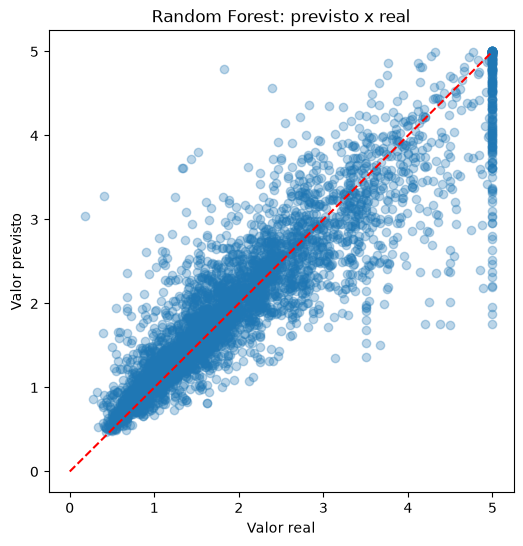

In [24]:
import matplotlib.pyplot as plt

melhor = modelos["Random Forest"]
p = melhor.predict(X_test_scaled)

plt.figure(figsize=(6, 6))
plt.scatter(Y_test, p, alpha=0.3)
plt.plot([0, 5], [0, 5], "r--")
plt.xlabel("Valor real")
plt.ylabel("Valor previsto")
plt.title("Random Forest: previsto x real")
plt.show()

## Conclusões
- Random Forest teve o melhor desempenho (R² = 0,81; RMSE ≈ US$ 50 mil), superando a Regressão Linear (R² = 0,61).
- Modelos de árvore capturam relações não lineares, como o efeito da localização no preço, que a regressão linear não consegue representar.
- O dataset limita o valor dos imóveis em US$ 500 mil (5.0). Isso cria a faixa vertical no gráfico e aumenta o erro nas casas mais caras.